# 🏠 Indian Housing (Synthetic) — Exploratory Data Analysis

**Dataset:** `indian_housing_synthetic_1k.csv` (1,000 properties, 6 cities, 30 localities)
**Target variable:** `price_lakhs` (price in ₹ Lakhs)

**Notebook ka flow:**
1. Setup & data loading
2. Data overview & quality checks
3. Univariate analysis
4. Bivariate analysis (features vs price)
5. City & locality analysis
6. Correlation analysis
7. Geographic analysis
8. Feature engineering insights
9. Key findings

## 1. Setup & Data Loading

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid', palette='viridis')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

In [2]:
# Agar file kisi aur jagah hai to path yahan change karein
DATA_PATH = 'indian_housing_synthetic_1k.csv'
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
df.head()

Shape: (1000, 13)


,city,locality,BHK,area,floor,total_floors,age,furnishing,latitude,longitude,distance_to_cbd_km,distance_to_metro_km,price_lakhs
0,Hyderabad,Jubilee Hills,2,871,4,5,20,Semi-Furnished,17.38,78.39,7.69,1.42,35.28
1,Kolkata,New Town,2,1076,14,18,3,Semi-Furnished,22.65,88.43,10.30,0.75,43.29
2,Bangalore,HSR Layout,2,1304,3,5,2,Semi-Furnished,12.98,77.56,4.02,0.72,93.64
3,Hyderabad,Jubilee Hills,3,1434,5,8,5,Unfurnished,17.43,78.40,2.91,0.19,84.89
4,Delhi,Saket,2,1001,14,21,10,Semi-Furnished,28.64,77.27,5.37,0.39,75.34


## 2. Data Overview & Quality Checks

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   city                  1000 non-null   str    
 1   locality              1000 non-null   str    
 2   BHK                   1000 non-null   int64  
 3   area                  1000 non-null   int64  
 4   floor                 1000 non-null   int64  
 5   total_floors          1000 non-null   int64  
 6   age                   1000 non-null   int64  
 7   furnishing            1000 non-null   str    
 8   latitude              1000 non-null   float64
 9   longitude             1000 non-null   float64
 10  distance_to_cbd_km    1000 non-null   float64
 11  distance_to_metro_km  1000 non-null   float64
 12  price_lakhs           1000 non-null   float64
dtypes: float64(5), int64(5), str(3)
memory usage: 101.7 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
BHK,"1,000.00",2.33,0.82,1.00,2.00,2.00,3.00,4.00
area,"1,000.00","1,391.80",708.42,403.00,929.75,"1,241.00","1,733.00","4,179.00"
floor,"1,000.00",8.09,7.89,0.00,2.00,6.00,11.25,42.00
total_floors,"1,000.00",18.14,11.41,3.00,9.00,16.00,26.00,44.00
age,"1,000.00",5.74,5.31,0.00,2.00,5.00,8.00,20.00
latitude,"1,000.00",19.07,5.55,12.80,13.06,18.97,22.58,28.79
longitude,"1,000.00",79.03,4.72,72.77,77.21,77.67,80.23,88.46
distance_to_cbd_km,"1,000.00",7.76,4.45,0.28,4.38,6.99,10.41,27.51
distance_to_metro_km,"1,000.00",1.25,0.71,0.10,0.70,1.24,1.74,3.73
price_lakhs,"1,000.00",116.19,112.12,11.00,48.71,79.69,135.22,"1,126.93"


In [5]:
# Categorical columns ka summary
df.describe(include='object').T

,count,unique,top,freq
city,1000,6,Delhi,176
locality,1000,30,Rohini,45
furnishing,1000,3,Semi-Furnished,542


In [6]:
# Missing values & duplicates
print('Missing values per column:')
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().any().any() else 'Koi missing value nahi ✅')
print('\nDuplicate rows:', df.duplicated().sum())

Missing values per column:
Koi missing value nahi ✅

Duplicate rows: 0


In [7]:
# Logical consistency checks
checks = {
    'floor > total_floors': (df['floor'] > df['total_floors']).sum(),
    'area <= 0': (df['area'] <= 0).sum(),
    'price <= 0': (df['price_lakhs'] <= 0).sum(),
    'negative distances': ((df['distance_to_cbd_km'] < 0) | (df['distance_to_metro_km'] < 0)).sum(),
}
pd.Series(checks, name='violations').to_frame()

,violations
floor > total_floors,0
area <= 0,0
price <= 0,0
negative distances,0


## 3. Univariate Analysis

### 3.1 Target variable: `price_lakhs`

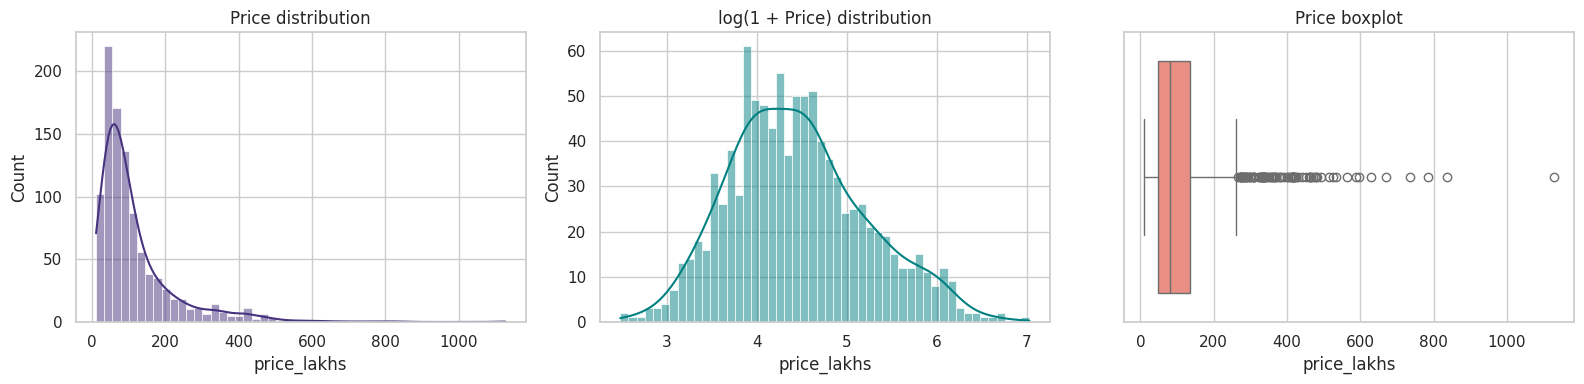

Skewness (raw): 2.88
Skewness (log): 0.40


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df['price_lakhs'], bins=50, kde=True, ax=ax[0])
ax[0].set_title('Price distribution')
sns.histplot(np.log1p(df['price_lakhs']), bins=50, kde=True, ax=ax[1], color='teal')
ax[1].set_title('log(1 + Price) distribution')
sns.boxplot(x=df['price_lakhs'], ax=ax[2], color='salmon')
ax[2].set_title('Price boxplot')
plt.tight_layout(); plt.show()

print(f"Skewness (raw): {df['price_lakhs'].skew():.2f}")
print(f"Skewness (log): {np.log1p(df['price_lakhs']).skew():.2f}")

> Price right-skewed hota hai (kuch bahut mehnge ghar). Log transform distribution ko normal ke kareeb le aata hai — modelling ke liye useful.

### 3.2 Numerical features

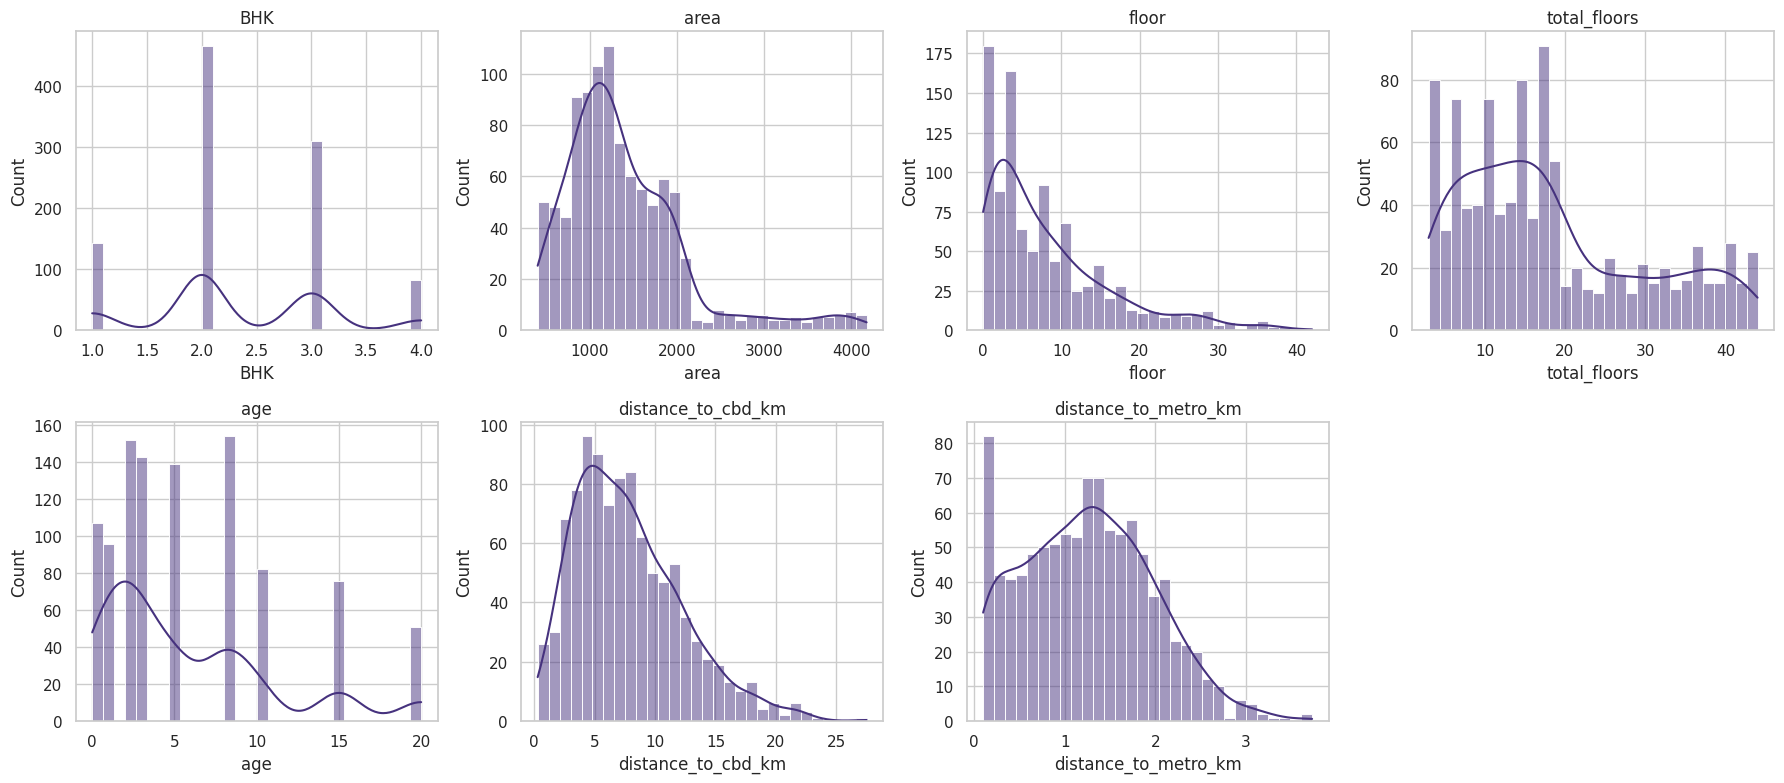

In [9]:
num_cols = ['BHK', 'area', 'floor', 'total_floors', 'age', 'distance_to_cbd_km', 'distance_to_metro_km']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(col)
axes.flat[-1].axis('off')
plt.tight_layout(); plt.show()

In [10]:
# Outlier detection (IQR method)
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()

out = pd.DataFrame({
    'outliers': {c: iqr_outliers(df[c]) for c in num_cols + ['price_lakhs']},
    'skew': {c: df[c].skew() for c in num_cols + ['price_lakhs']},
})
out['outlier_%'] = out['outliers'] / len(df) * 100
out

,outliers,skew,outlier_%
BHK,0,0.22,0.00
area,50,1.61,5.00
floor,53,1.46,5.30
total_floors,0,0.72,0.00
age,51,1.18,5.10
distance_to_cbd_km,17,0.87,1.70
distance_to_metro_km,4,0.31,0.40
price_lakhs,91,2.88,9.10


### 3.3 Categorical features

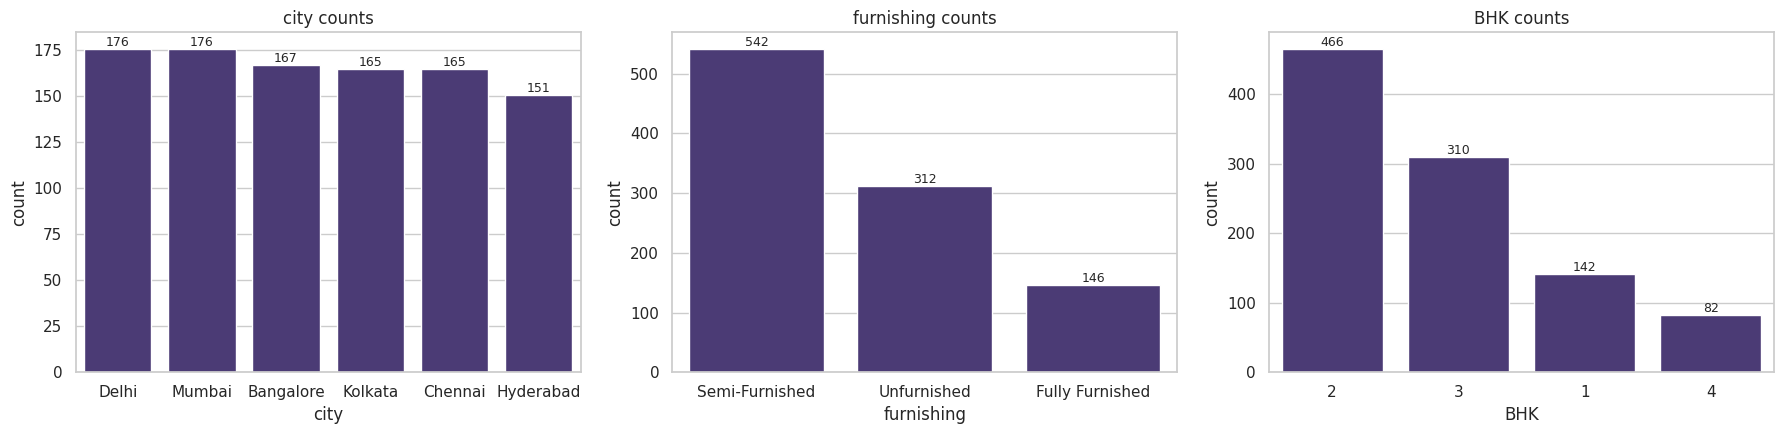

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, ['city', 'furnishing', 'BHK']):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax)
    ax.set_title(f'{col} counts')
    for p in ax.patches:
        ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.show()

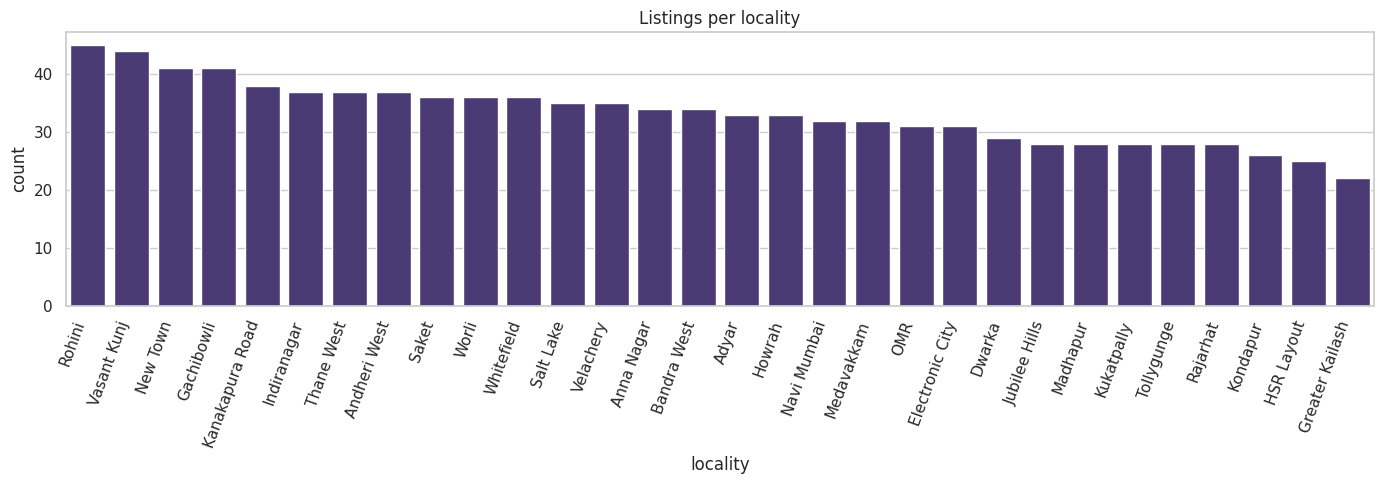

In [12]:
plt.figure(figsize=(14, 5))
order = df['locality'].value_counts().index
sns.countplot(data=df, x='locality', order=order)
plt.xticks(rotation=70, ha='right'); plt.title('Listings per locality')
plt.tight_layout(); plt.show()

## 4. Bivariate Analysis — Features vs Price

### 4.1 Numerical features vs price

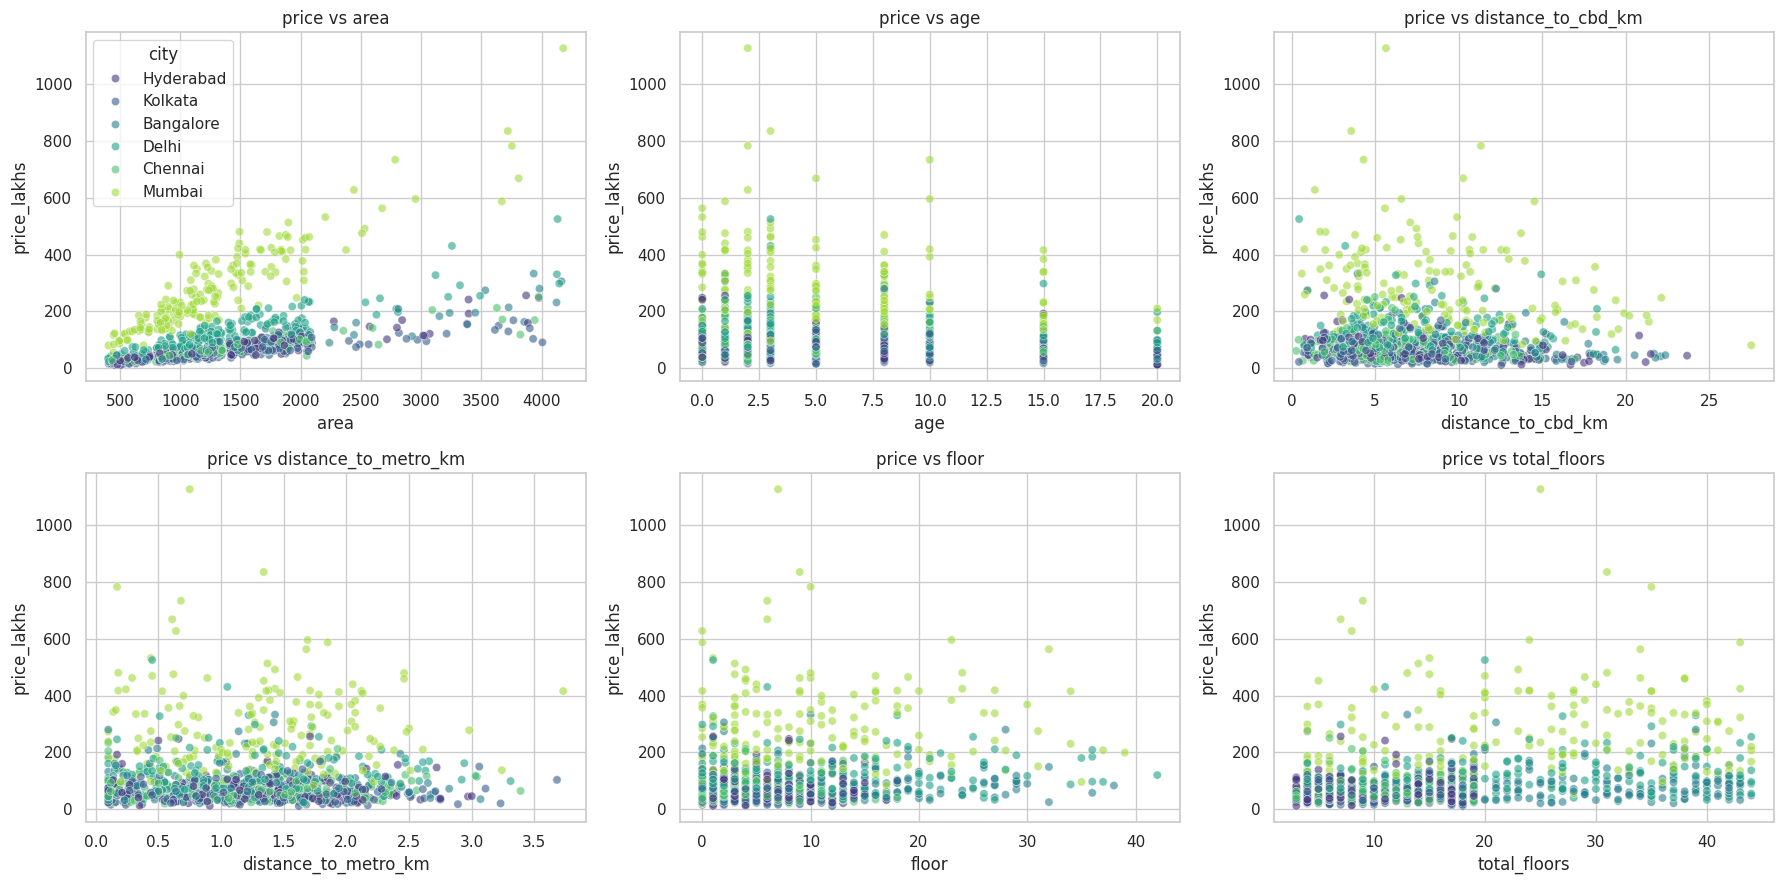

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flat, ['area', 'age', 'distance_to_cbd_km', 'distance_to_metro_km', 'floor', 'total_floors']):
    sns.scatterplot(data=df, x=col, y='price_lakhs', hue='city', alpha=.6, ax=ax, legend=(col == 'area'))
    ax.set_title(f'price vs {col}')
plt.tight_layout(); plt.show()

### 4.2 Categorical features vs price

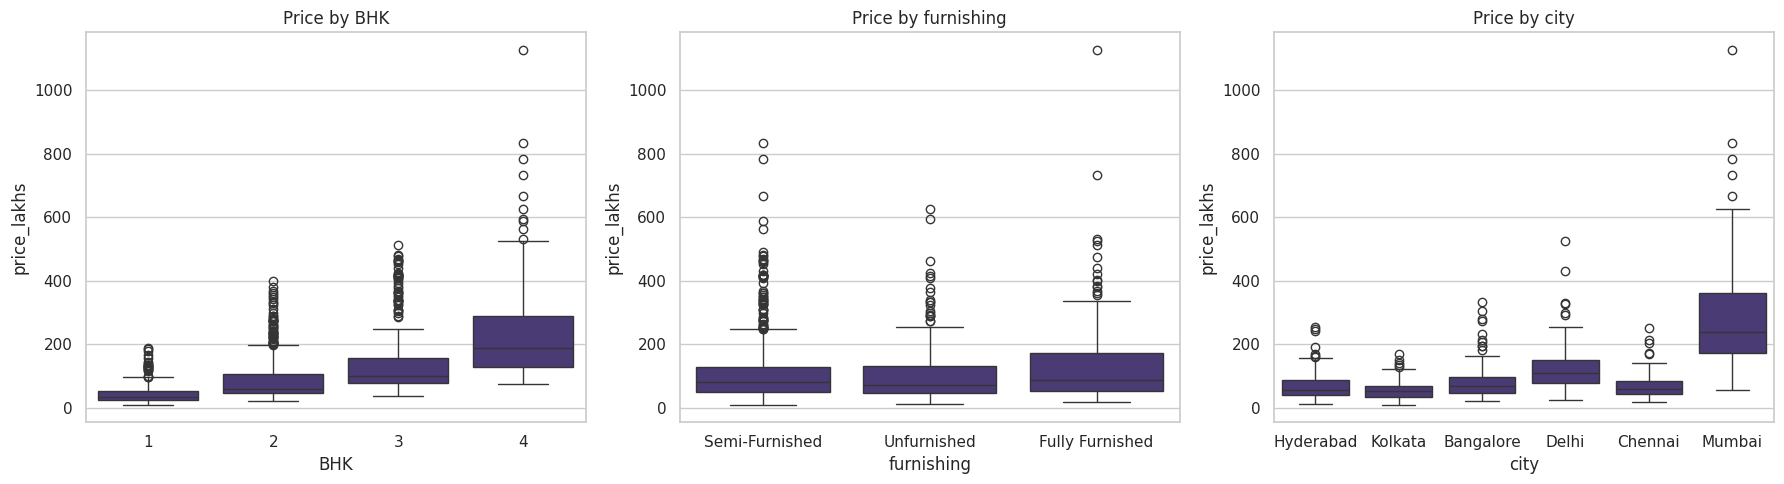

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=df, x='BHK', y='price_lakhs', ax=axes[0]); axes[0].set_title('Price by BHK')
sns.boxplot(data=df, x='furnishing', y='price_lakhs', ax=axes[1]); axes[1].set_title('Price by furnishing')
sns.boxplot(data=df, x='city', y='price_lakhs', ax=axes[2]); axes[2].set_title('Price by city')
plt.tight_layout(); plt.show()

In [15]:
# Furnishing ka asar — kya statistically significant hai? (ANOVA on log price)
groups = [np.log(g['price_lakhs']) for _, g in df.groupby('furnishing')]
f, p = stats.f_oneway(*groups)
print(f'ANOVA (furnishing vs log price): F={f:.2f}, p={p:.4f}')
print('Significant ✅' if p < 0.05 else 'Furnishing ka overall asar significant nahi ❌')
df.groupby('furnishing')['price_lakhs'].agg(['count', 'mean', 'median']).round(2)

ANOVA (furnishing vs log price): F=6.30, p=0.0019
Significant ✅


,count,mean,median
furnishing,,,
Fully Furnished,146,143.36,87.63
Semi-Furnished,542,117.34,80.94
Unfurnished,312,101.47,71.90


## 5. City & Locality Analysis

In [16]:
city_stats = df.groupby('city').agg(
    listings=('price_lakhs', 'size'),
    avg_price=('price_lakhs', 'mean'),
    median_price=('price_lakhs', 'median'),
    avg_area=('area', 'mean'),
    avg_age=('age', 'mean'),
).round(2)
city_stats['price_per_sqft'] = (df.groupby('city').apply(lambda g: g['price_lakhs'].sum()*1e5 / g['area'].sum())).round(0)
city_stats.sort_values('median_price', ascending=False)

,listings,avg_price,median_price,avg_area,avg_age,price_per_sqft
city,,,,,,
Mumbai,176,282.68,240.84,"1,314.10",5.40,"21,511.00"
Delhi,176,124.65,109.90,"1,380.57",6.10,"9,029.00"
Bangalore,167,82.28,70.28,"1,456.68",5.95,"5,648.00"
Chennai,165,67.63,59.13,"1,378.04",5.36,"4,908.00"
Hyderabad,151,68.55,55.28,"1,382.04",6.11,"4,960.00"
Kolkata,165,56.05,52.99,"1,443.70",5.52,"3,882.00"


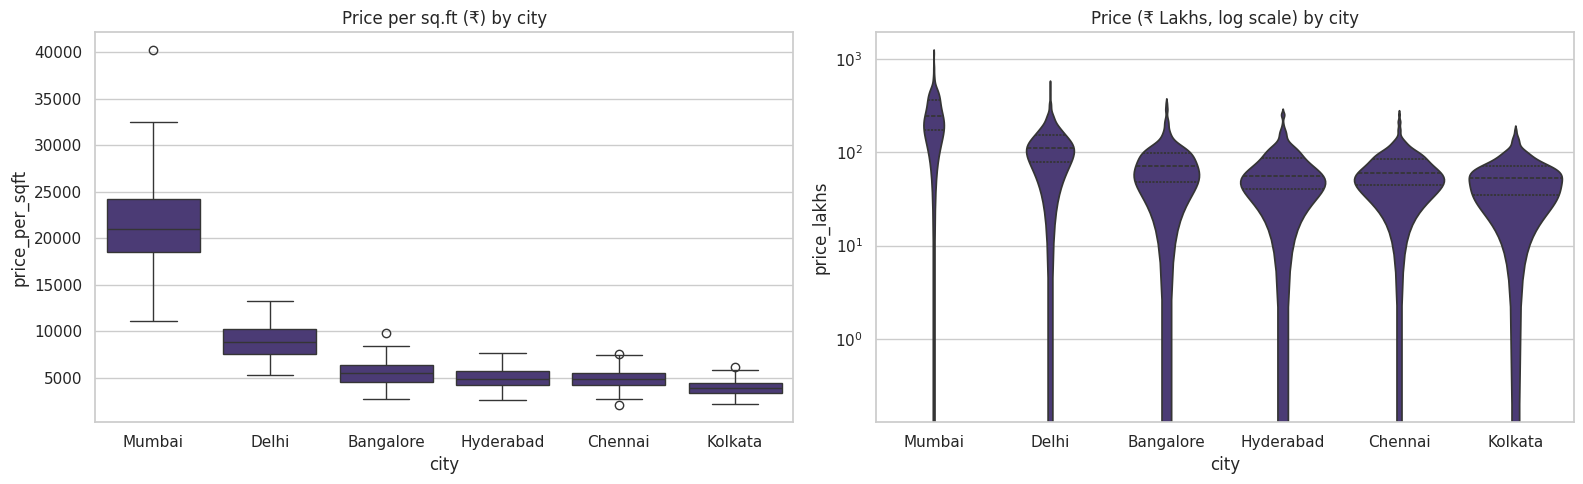

In [17]:
df['price_per_sqft'] = df['price_lakhs'] * 1e5 / df['area']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
order = df.groupby('city')['price_per_sqft'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='city', y='price_per_sqft', order=order, ax=axes[0])
axes[0].set_title('Price per sq.ft (₹) by city')
sns.violinplot(data=df, x='city', y='price_lakhs', order=order, ax=axes[1], inner='quartile')
axes[1].set_yscale('log'); axes[1].set_title('Price (₹ Lakhs, log scale) by city')
plt.tight_layout(); plt.show()

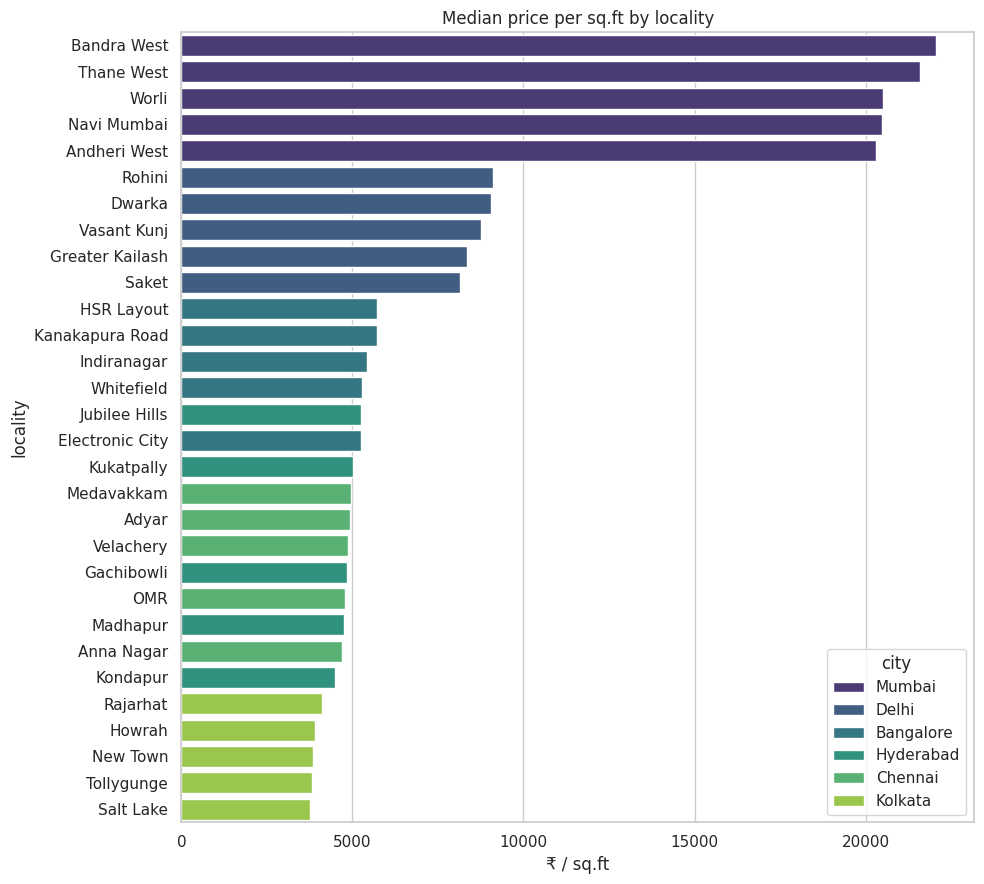

,city,locality,n,median_ppsf,median_price
26,Mumbai,Bandra West,34,"22,066.11",330.04
28,Mumbai,Thane West,37,"21,593.02",233.53
29,Mumbai,Worli,36,"20,515.84",235.93
27,Mumbai,Navi Mumbai,32,"20,484.71",235.75
25,Mumbai,Andheri West,37,"20,318.16",230.45
12,Delhi,Rohini,45,"9,100.49",127.88
10,Delhi,Dwarka,29,"9,042.32",107.52
14,Delhi,Vasant Kunj,44,"8,765.48",116.71
11,Delhi,Greater Kailash,22,"8,363.32",94.16
13,Delhi,Saket,36,"8,150.44",106.70


In [18]:
# Top & bottom localities by median price per sq.ft
loc = (df.groupby(['city', 'locality'])
         .agg(n=('price_per_sqft', 'size'), median_ppsf=('price_per_sqft', 'median'), median_price=('price_lakhs', 'median'))
         .reset_index().sort_values('median_ppsf', ascending=False))
plt.figure(figsize=(10, 9))
sns.barplot(data=loc, y='locality', x='median_ppsf', hue='city', dodge=False)
plt.title('Median price per sq.ft by locality'); plt.xlabel('₹ / sq.ft')
plt.tight_layout(); plt.show()
loc.head(10)

## 6. Correlation Analysis

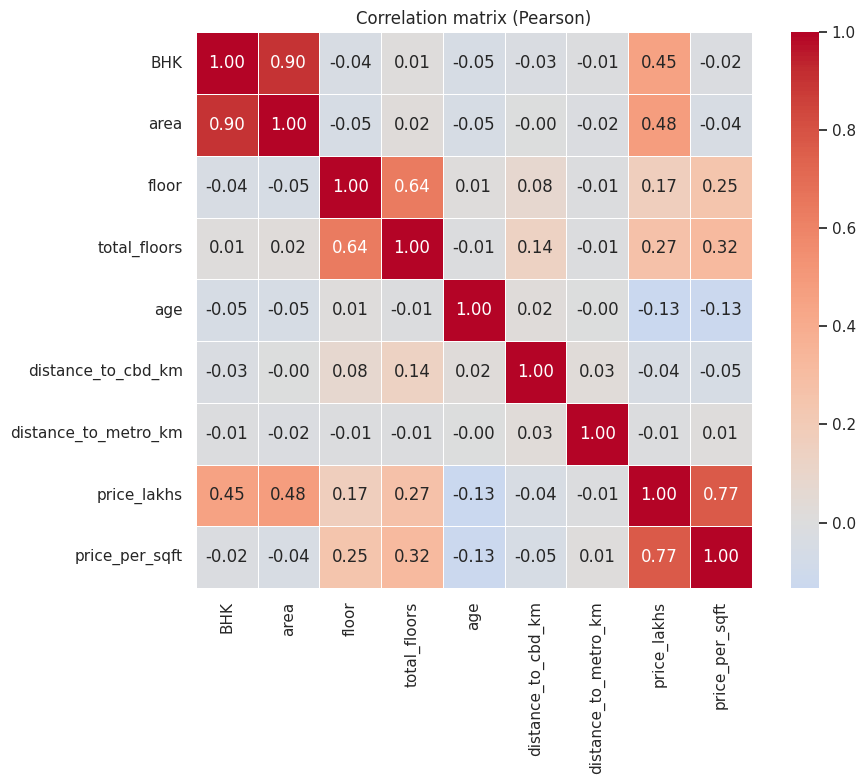

In [19]:
corr_cols = num_cols + ['price_lakhs', 'price_per_sqft']
corr = df[corr_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, linewidths=.5)
plt.title('Correlation matrix (Pearson)'); plt.tight_layout(); plt.show()

In [20]:
# Spearman correlation with price (non-linear/monotonic relationships ke liye)
sp = df[num_cols].apply(lambda s: stats.spearmanr(s, df['price_lakhs'])[0]).sort_values(key=abs, ascending=False)
sp.rename('spearman_with_price').to_frame()

,spearman_with_price
area,0.58
BHK,0.57
total_floors,0.30
floor,0.18
age,-0.13
distance_to_cbd_km,-0.06
distance_to_metro_km,-0.00


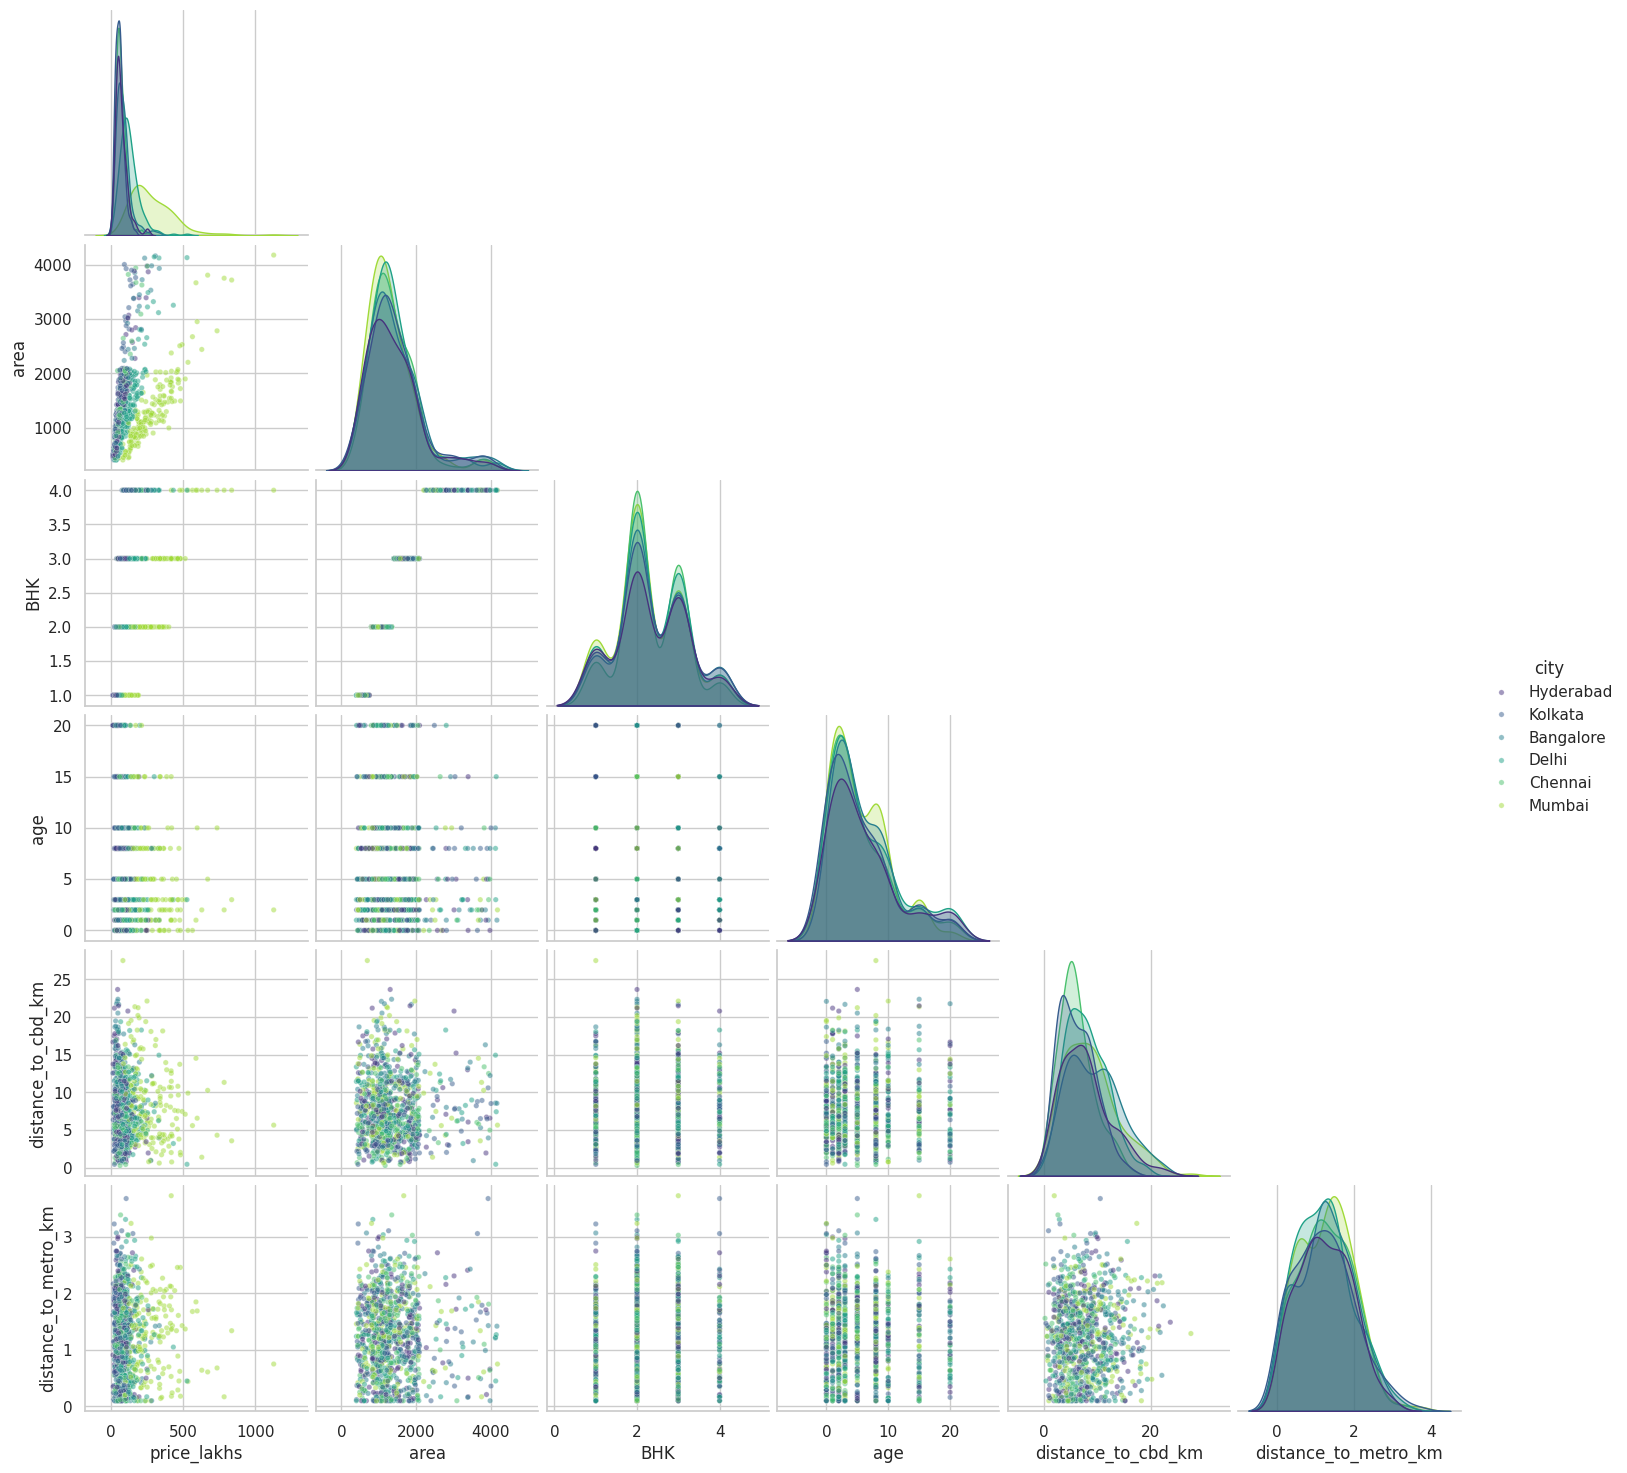

In [21]:
# Pairplot of key variables
sns.pairplot(df[['price_lakhs', 'area', 'BHK', 'age', 'distance_to_cbd_km', 'distance_to_metro_km']].assign(city=df['city']),
             hue='city', corner=True, plot_kws={'alpha': .5, 's': 15})
plt.show()

## 7. Geographic Analysis

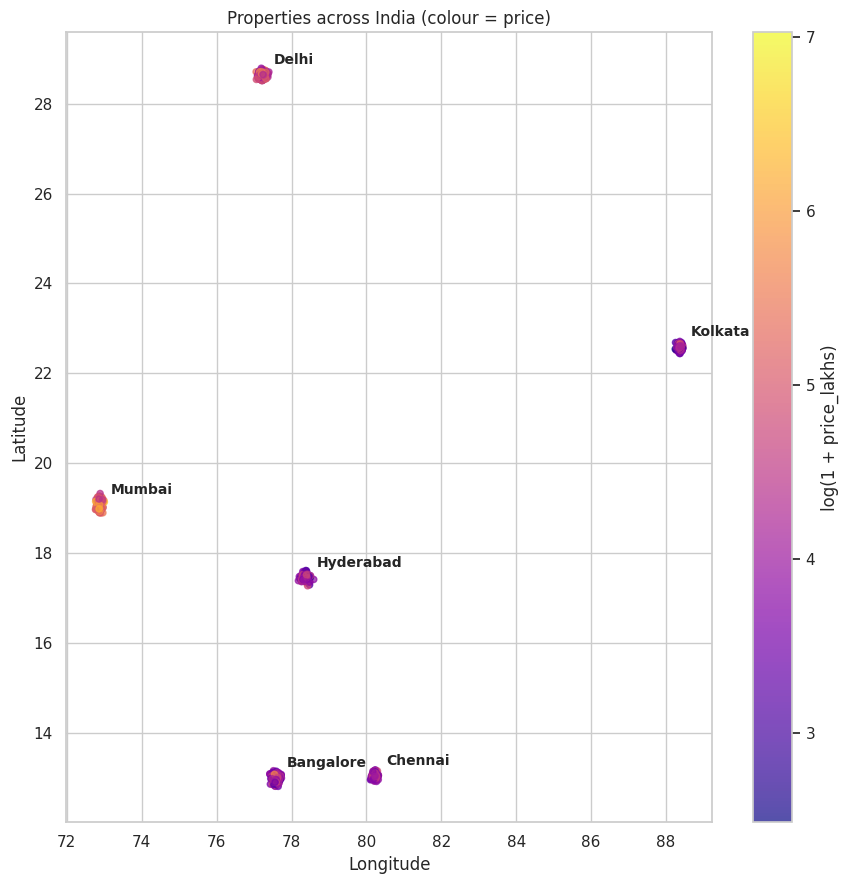

In [22]:
plt.figure(figsize=(9, 9))
sc = plt.scatter(df['longitude'], df['latitude'], c=np.log1p(df['price_lakhs']), cmap='plasma', s=20, alpha=.7)
plt.colorbar(sc, label='log(1 + price_lakhs)')
plt.xlabel('Longitude'); plt.ylabel('Latitude'); plt.title('Properties across India (colour = price)')
for city, g in df.groupby('city'):
    plt.annotate(city, (g['longitude'].mean(), g['latitude'].mean()), fontsize=10, weight='bold',
                 xytext=(8, 8), textcoords='offset points')
plt.tight_layout(); plt.show()

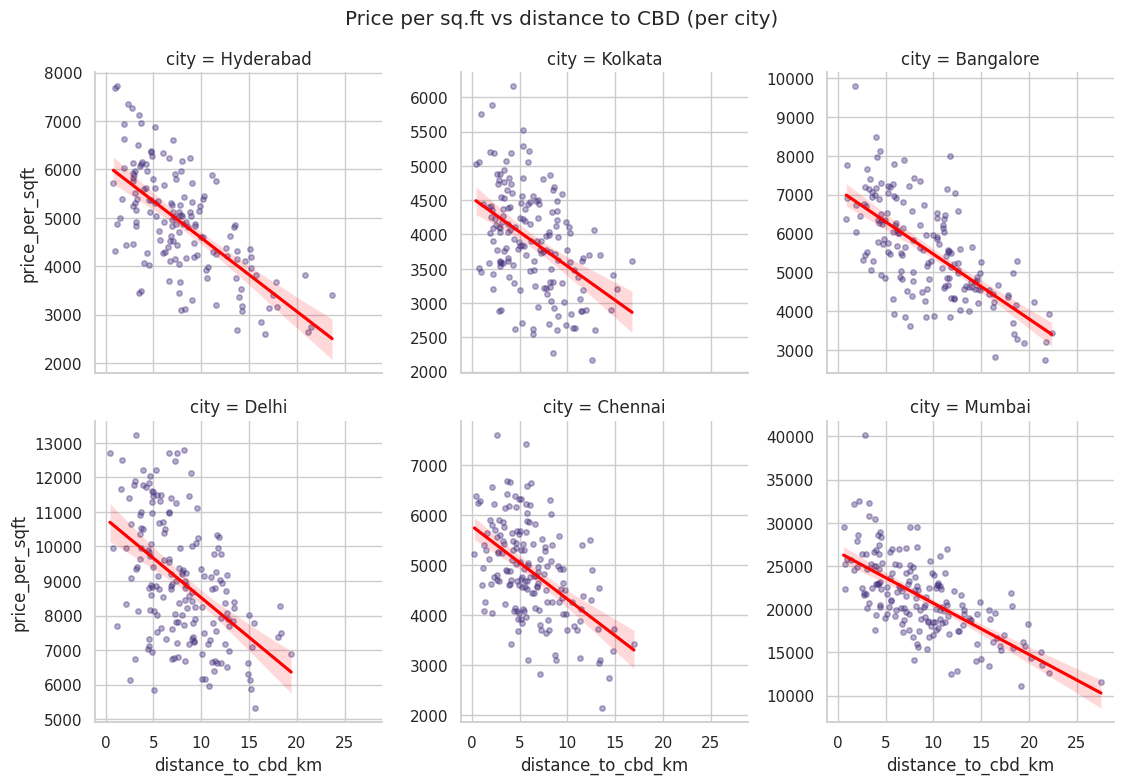

In [23]:
# Har city ke andar: CBD se doori ka price par asar
g = sns.lmplot(data=df, x='distance_to_cbd_km', y='price_per_sqft', col='city', col_wrap=3,
               height=3.8, sharey=False, scatter_kws={'alpha': .4, 's': 15}, line_kws={'color': 'red'})
g.fig.suptitle('Price per sq.ft vs distance to CBD (per city)', y=1.03); plt.show()

            count   median
metro_band                
<0.5km        180 5,741.00
0.5-1km       204 5,484.00
1-2km         460 5,758.00
>2km          156 5,611.00


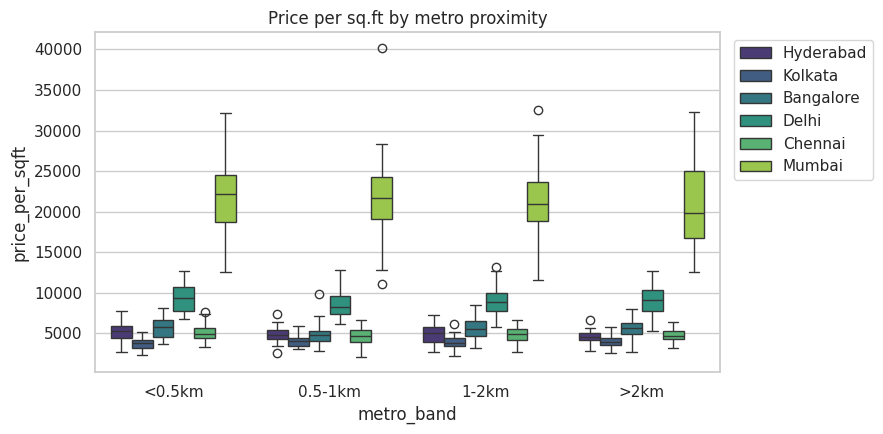

In [24]:
# Metro ke paas hone ka premium
df['metro_band'] = pd.cut(df['distance_to_metro_km'], [0, 0.5, 1, 2, 5], labels=['<0.5km', '0.5-1km', '1-2km', '>2km'])
print(df.groupby('metro_band', observed=True)['price_per_sqft'].agg(['count', 'median']).round(0))

plt.figure(figsize=(9, 4.5))
sns.boxplot(data=df, x='metro_band', y='price_per_sqft', hue='city')
plt.title('Price per sq.ft by metro proximity'); plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout(); plt.show()

## 8. Feature Engineering Insights

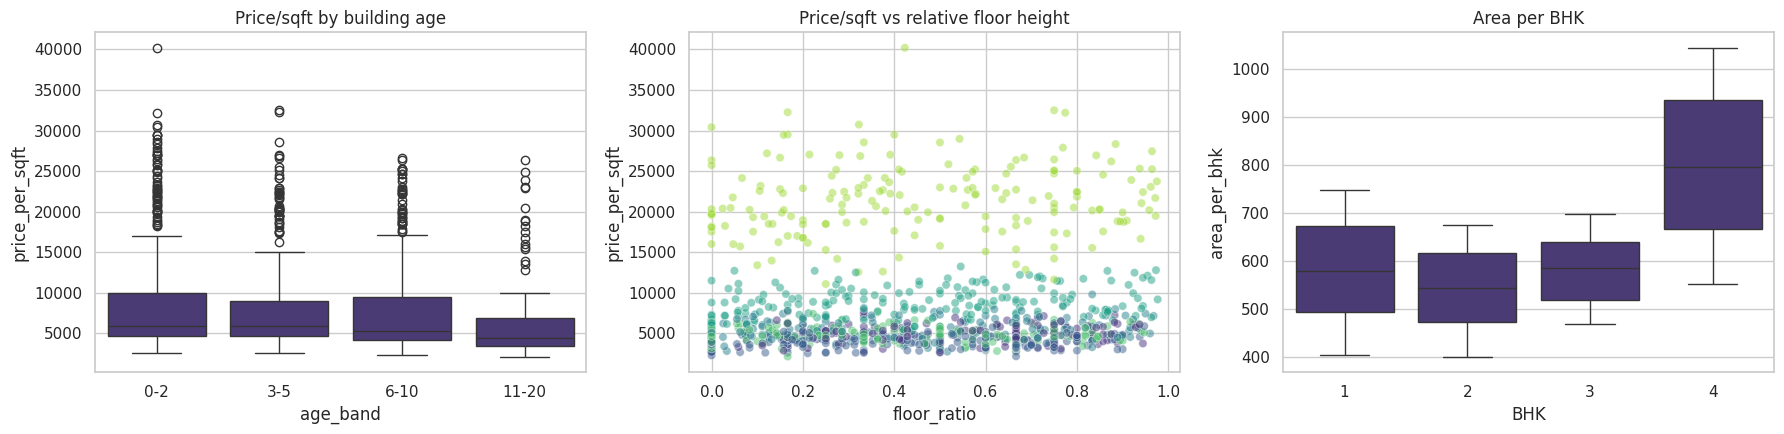

In [25]:
df['floor_ratio'] = df['floor'] / df['total_floors']
df['age_band'] = pd.cut(df['age'], [-1, 2, 5, 10, 20], labels=['0-2', '3-5', '6-10', '11-20'])
df['area_per_bhk'] = df['area'] / df['BHK']

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.boxplot(data=df, x='age_band', y='price_per_sqft', ax=axes[0]); axes[0].set_title('Price/sqft by building age')
sns.scatterplot(data=df, x='floor_ratio', y='price_per_sqft', hue='city', alpha=.5, ax=axes[1], legend=False)
axes[1].set_title('Price/sqft vs relative floor height')
sns.boxplot(data=df, x='BHK', y='area_per_bhk', ax=axes[2]); axes[2].set_title('Area per BHK')
plt.tight_layout(); plt.show()

In [26]:
# Feature quality check: engineered features ka correlation price_per_sqft ke saath
df[['floor_ratio', 'area_per_bhk', 'age', 'distance_to_cbd_km', 'distance_to_metro_km', 'price_per_sqft']].corr()['price_per_sqft'].drop('price_per_sqft').sort_values(key=abs, ascending=False).to_frame('corr_with_price_per_sqft')

,corr_with_price_per_sqft
age,-0.13
floor_ratio,0.07
distance_to_cbd_km,-0.05
area_per_bhk,-0.05
distance_to_metro_km,0.01


## 9. Key Findings

In [27]:
top_city = df.groupby('city')['price_per_sqft'].median().sort_values()
print('📌 KEY FINDINGS\n' + '-'*60)
print(f"1. Dataset: {len(df):,} rows, {df['city'].nunique()} cities, {df['locality'].nunique()} localities; missing values: {int(df.isna().sum().sum())}.")
print(f"2. Price right-skewed (skew={df['price_lakhs'].skew():.2f}); log transform reduces it to {np.log1p(df['price_lakhs']).skew():.2f}.")
print(f"3. Sabse mehnga city (median ₹/sqft): {top_city.index[-1]} (₹{top_city.iloc[-1]:,.0f}); sabse sasta: {top_city.index[0]} (₹{top_city.iloc[0]:,.0f}).")
print(f"4. Price ke sabse strong numeric correlates (Spearman): " + ', '.join(f'{k} ({v:.2f})' for k, v in sp.head(3).items()))
print(f"5. Area aur BHK price ke sabse bade drivers hain; city ka effect bhi bahut strong hai.")
print(f"6. CBD distance badhne par price/sqft aam taur par girta hai — har city mein alag slope.")
print("\n➡️ Next step: log(price) par city/locality encoding ke saath regression ya gradient boosting model try karein.")

📌 KEY FINDINGS
------------------------------------------------------------
1. Dataset: 1,000 rows, 6 cities, 30 localities; missing values: 0.
2. Price right-skewed (skew=2.88); log transform reduces it to 0.40.
3. Sabse mehnga city (median ₹/sqft): Mumbai (₹21,024); sabse sasta: Kolkata (₹3,905).
4. Price ke sabse strong numeric correlates (Spearman): area (0.58), BHK (0.57), total_floors (0.30)
5. Area aur BHK price ke sabse bade drivers hain; city ka effect bhi bahut strong hai.
6. CBD distance badhne par price/sqft aam taur par girta hai — har city mein alag slope.

➡️ Next step: log(price) par city/locality encoding ke saath regression ya gradient boosting model try karein.
